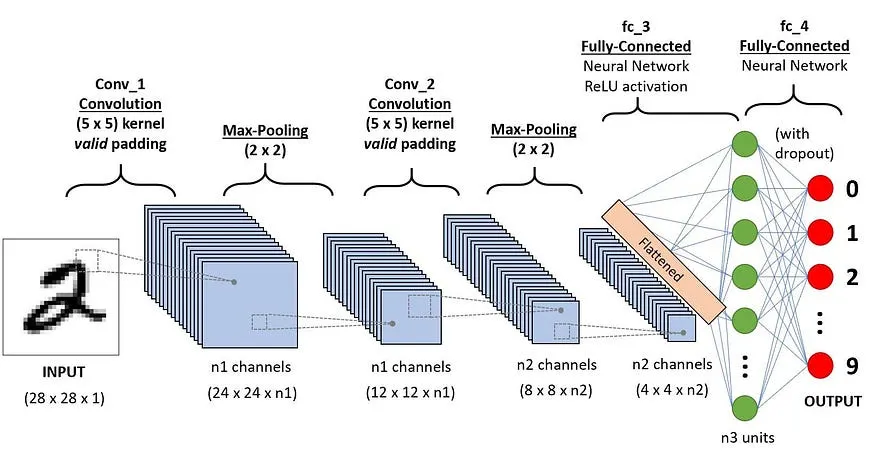

In [1]:
!pip3 install mnist



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import mnist

In [3]:
#обычный слой свертки, который работает работае линейно
class convolutional_layer:
    def __init__(self, num_filters):
        self.num_filters = num_filters
        self.filters = np.random.randn(num_filters, 3, 3) / 9 

    def iterate_regions(self, image):
        h, w = image.shape
        for i in range(h-2):
            for j in range(w-2):
                im_region = image[i:(i+3), j:(j+3)]
                yield im_region, i, j
    
    def forward(self, input):

        self.last_input = input
        h, w = input.shape
        output = np.zeros((h - 2, w - 2, self.num_filters))

        for im_region, i, j in self.iterate_regions(input):
            output[i, j] = np.sum(im_region * self.filters, axis = (1,2) )

        return output 

    def backprob(self, dl_dout, learn_rate):
        dl_dfilters = np.zeros(self.filters.shape)
        for im_region, i, j in self.iterate_regions(self.last_input):
            for f in range(self.num_filters):
                dl_dfilters[f] += dl_dout[i, j, f] * im_region
        self.filters -= learn_rate * dl_dfilters

        return None




In [4]:
# class maxpoool whitch return max value from grid
class MaxPoll:
    def iterate_regions(self, image):
        h, w, _ = image.shape
        h_2 = h // 2
        w_2 = w// 2

        for i in range(h_2):
            for j in range(w_2):
                im_region = image[(i * 2):(i * 2 + 2), (j * 2):(j * 2 + 2)]
                yield im_region, i, j

    def backprob(self, dl_dout):
        dl_dinput =  np.zeros(self.last_input.shape)

        for im_region, i, j in self.iterate_regions(self.last_input):
            h, w, f = im_region.shape
            amax = np.amax(im_region, axis=(0, 1))

            for i2 in range(h):
                for j2 in range(w):
                    for f2 in range(f):
                        if im_region[i2, j2, f2] == amax[f2]:
                            dl_dinput[i * 2 + i2, j * 2 + j2, f2] = dl_dout[i, j, f2]
        return dl_dinput 

    def forward(self, input):

        self.last_input = input

        h, w, num_filters = input.shape
        output = np.zeros((h // 2, w // 2, num_filters))

        for im_region, i, j in self.iterate_regions(input):
            output[i, j] = np.amax(im_region, axis=(0 ,1))

        return output        

![alt text](image.png)

In [5]:
# pick the digit with the highest output from the network
# softmax helps us quantify how sure we r of our prediction, which is useful when trining and evaluating CNN
class SoftMax:
    def __init__(self, input_len, nodes):
        self.weights = np.random.randn(input_len, nodes) / input_len
        self.biases = np.zeros(nodes)

    def forward(self, input):
        self.last_input_shape = input.shape

        input = input.flatten()
        self.last_input = input

        input_len, nodes = self.weights.shape

        totals = np.dot(input, self.weights) + self.biases
        self.last_totals = totals
        
        exp = np.exp(totals)
        return exp/np.sum(exp, axis=0)

    def backprob(self, dl_dout, learning_rate):
        for i, gradient in enumerate(dl_dout):
            if gradient == 0:
                continue

            # e^totals
            t_exp = np.exp(self.last_totals)

            #sum
            S = np.sum(t_exp)

            dout_dt = - t_exp[i] * t_exp / (S ** 2)
            dout_dt[i] = t_exp[i] * (S - t_exp[i]) / S ** 2

            # Gradients of totals against weights/biases/input
            dt_dw = self.last_input
            dt_db = 1
            dt_dinput = self.weights

            # Gradients of loss against totals
            dl_dt = gradient * dout_dt

            # Gradients of loss against weights/biases/input
            dl_dw = dt_dw[np.newaxis].T @ dl_dt[np.newaxis]
            dl_db = dl_dt * dt_db
            dl_dinputs = dt_dinput @ dl_dt

            self.weights -= learning_rate * dl_dw
            self.biases -= learning_rate * dl_db
            return dl_dinputs.reshape(self.last_input_shape)


    

In [6]:
mnist.datasets_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"

train_images = mnist.train_images()[:1000]
train_labels = mnist.train_labels()[:1000]
test_images = mnist.test_images()[:1000]
test_labels = mnist.test_labels()[:1000]

conv = convolutional_layer(8)
pool = MaxPoll()
softmax = SoftMax(13 * 13 * 8, 10)

# feed forward
def forward(image, label):
  '''
  Completes a forward pass of the CNN and calculates the accuracy and
  cross-entropy loss.
  - image is a 2d numpy array
  - label is a digit
  '''
  # We transform the image from [0, 255] to [-0.5, 0.5] to make it easier
  # to work with. This is standard practice.
  out = conv.forward((image / 255) - 0.5)
  out = pool.forward(out)
  out = softmax.forward(out)

  # Calculate cross-entropy loss and accuracy. np.log() is the natural log.
  loss = -np.log(out[label])
  acc = 1 if np.argmax(out) == label else 0

  return out, loss, acc

def train(im, label, lr=.005):
  '''
  Completes a full training step on the given image and label.
  Returns the cross-entropy loss and accuracy.
  - image is a 2d numpy array
  - label is a digit
  - lr is the learning rate
  '''
  # Forward
  out, loss, acc = forward(im, label)

  # Calculate initial gradient
  gradient = np.zeros(10)
  gradient[label] = -1 / out[label]

  # Backprob
  gradient = softmax.backprob(gradient, lr)
  gradient = pool.backprob(gradient)
  gradient = conv.backprob(gradient, lr)

  return loss, acc

print('MNIST CNN initialized!')

# Train the CNN for 3 epochs
for epoch in range(3):
  print('--- Epoch %d ---' % (epoch + 1))

  # Shuffle the training data
  permutation = np.random.permutation(len(train_images))
  train_images = train_images[permutation]
  train_labels = train_labels[permutation]

  # Train!
  loss = 0
  num_correct = 0
  for i, (im, label) in enumerate(zip(train_images, train_labels)):
    if i > 0 and i % 100 == 99:
      print(
        '[Step %d] Past 100 steps: Average Loss %.3f | Accuracy: %d%%' %
        (i + 1, loss / 100, num_correct)
      )
      loss = 0
      num_correct = 0

    l, acc = train(im, label)
    loss += l
    num_correct += acc

# Test the CNN
print('\n--- Testing the CNN ---')
loss = 0
num_correct = 0
for im, label in zip(test_images, test_labels):
  _, l, acc = forward(im, label)
  loss += l
  num_correct += acc

num_tests = len(test_images)
print('Test Loss:', loss / num_tests)
print('Test Accuracy:', num_correct / num_tests)

MNIST CNN initialized!
--- Epoch 1 ---
[Step 100] Past 100 steps: Average Loss 2.266 | Accuracy: 16%
[Step 200] Past 100 steps: Average Loss 2.222 | Accuracy: 23%
[Step 300] Past 100 steps: Average Loss 2.004 | Accuracy: 43%
[Step 400] Past 100 steps: Average Loss 1.443 | Accuracy: 61%
[Step 500] Past 100 steps: Average Loss 1.001 | Accuracy: 78%
[Step 600] Past 100 steps: Average Loss 1.001 | Accuracy: 65%
[Step 700] Past 100 steps: Average Loss 0.692 | Accuracy: 76%
[Step 800] Past 100 steps: Average Loss 0.836 | Accuracy: 74%
[Step 900] Past 100 steps: Average Loss 0.611 | Accuracy: 80%
[Step 1000] Past 100 steps: Average Loss 0.779 | Accuracy: 77%
--- Epoch 2 ---
[Step 100] Past 100 steps: Average Loss 0.543 | Accuracy: 85%
[Step 200] Past 100 steps: Average Loss 0.673 | Accuracy: 75%
[Step 300] Past 100 steps: Average Loss 0.511 | Accuracy: 84%
[Step 400] Past 100 steps: Average Loss 0.435 | Accuracy: 89%
[Step 500] Past 100 steps: Average Loss 0.605 | Accuracy: 82%
[Step 600] Pas

In [ ]:
train_images = mnist.train_images()[:1000]

test_conv = convolutional_layer(num_filters=6, kernel_size=5)

# Изображение 28×28 дополняем до 32×32.
image = np.pad(train_images[0], ((2, 2), (2, 2)))

# Нормализуем значения пикселей.
image = (image / 255) - 0.5

# Пропускаем изображение через первую свёртку.
output = test_conv.forward(image)
print(output.shape)  # (28, 28, 6)